**Nama:** Jordan Sebastian Simatupang  |  **NRP:** 5054251038

# Tugas Praktikum 3: Classification dengan Ensemble Method & Class Imbalance

**Dataset:** Credit Card Fraud Detection (Kaggle, `creditcard.csv`)
**Tujuan:** membangun model klasifikasi ensemble (Random Forest & Gradient Boosting) pada data yang sangat tidak seimbang, lalu membandingkan model **tanpa** dan **dengan** penanganan class imbalance (SMOTE, Random Undersampling, dan cost-sensitive learning).

**Alur notebook**
1. Import & eksplorasi dataset
2. Praproses data (distribusi kelas, split 80:20 stratified, scaling, resampling hanya pada data latih)
3. Membangun model (Random Forest & Gradient Boosting)
4. Evaluasi (Precision, Recall, F1, AUC-ROC, AUC-PR, confusion matrix)
5. Mengapa accuracy saja tidak cukup
6. Kesimpulan

## 1. Import Library & Konfigurasi

In [2]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             ConfusionMatrixDisplay, roc_curve, precision_recall_curve,
                             classification_report)

from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42

# Cari file dataset (lokal / Google Colab / path lain)
DATA_PATH = "creditcard.csv"
for p in ["creditcard.csv", "/content/creditcard.csv", "/mnt/user-data/uploads/creditcard.csv"]:
    if os.path.exists(p):
        DATA_PATH = p
        break
print("Dataset:", DATA_PATH)

Dataset: creditcard.csv


## 2. Unduh dan Import Dataset

In [3]:
df = pd.read_csv(DATA_PATH)
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [4]:
print("Shape:", df.shape)

Shape: (284807, 31)


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

**Keterangan kolom:** `Time` (detik sejak transaksi pertama), `V1`–`V28` (hasil PCA, sudah dianonimkan), `Amount` (nominal transaksi), dan `Class` (target: 0 = normal, 1 = fraud).

In [6]:
print("Missing value total :", df.isna().sum().sum())
print("Baris duplikat      :", df.duplicated().sum())
df[["Time", "Amount"]].describe().T

Missing value total : 0
Baris duplikat      : 1081


,count,mean,std,min,25%,50%,75%,max
Time,284807.0,94813.859575,47488.145955,0.0,54201.5,84692.0,139320.500,172792.00
Amount,284807.0,88.349619,250.120109,0.0,5.6,22.0,77.165,25691.16


## 3. Praproses Data

### 3.1 Distribusi kelas awal

In [7]:
counts = df["Class"].value_counts().sort_index()
pct = df["Class"].value_counts(normalize=True).sort_index() * 100
dist = pd.DataFrame({"Jumlah": counts, "Persentase (%)": pct.round(4)})
dist.index = ["0 (Normal)", "1 (Fraud)"]
display(dist)
print(f"Rasio Normal : Fraud = {counts[0]/counts[1]:.0f} : 1")

,Jumlah,Persentase (%)
0 (Normal),284315,99.8273
1 (Fraud),492,0.1727


Rasio Normal : Fraud = 578 : 1


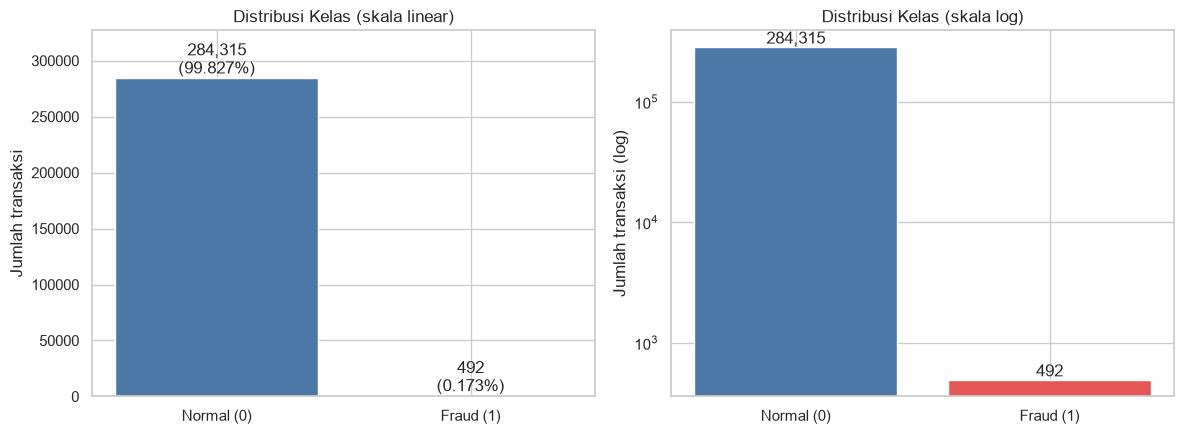

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
labels = ["Normal (0)", "Fraud (1)"]
colors = ["#4C78A8", "#E45756"]

ax[0].bar(labels, counts.values, color=colors)
ax[0].set_title("Distribusi Kelas (skala linear)")
ax[0].set_ylabel("Jumlah transaksi")
for i, v in enumerate(counts.values):
    ax[0].text(i, v, f"{v:,}\n({pct.values[i]:.3f}%)", ha="center", va="bottom")
ax[0].set_ylim(0, counts.max() * 1.15)

ax[1].bar(labels, counts.values, color=colors)
ax[1].set_yscale("log")
ax[1].set_title("Distribusi Kelas (skala log)")
ax[1].set_ylabel("Jumlah transaksi (log)")
for i, v in enumerate(counts.values):
    ax[1].text(i, v, f"{v:,}", ha="center", va="bottom")

plt.tight_layout()
plt.show()

Data **sangat tidak seimbang**: fraud hanya sekitar 0,17% dari seluruh transaksi. Model yang tidak ditangani akan cenderung bias ke kelas mayoritas.

### 3.2 Duplikat, scaling, dan pembagian data

- Baris duplikat dihapus **sebelum** split agar baris yang sama tidak muncul di data latih sekaligus data uji (menghindari *data leakage* yang membuat skor tampak lebih bagus dari kenyataan). Set `DROP_DUPLICATES = False` jika ingin memakai seluruh 284.807 baris.
- `Time` dan `Amount` belum berskala seperti `V1`–`V28`, sehingga di-scale dengan `RobustScaler` (tahan terhadap outlier pada `Amount`). Scaler **di-fit hanya pada data latih**.
- Split 80:20 dengan `stratify=y` agar proporsi fraud sama di data latih dan data uji.

In [9]:
DROP_DUPLICATES = True

data = df.drop_duplicates().reset_index(drop=True) if DROP_DUPLICATES else df.copy()
print(f"Baris sebelum: {len(df):,} | sesudah: {len(data):,} | fraud: {data['Class'].sum()}")

X = data.drop(columns="Class")
y = data["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

# Scaling Time & Amount (fit hanya di data latih)
scaler = RobustScaler()
X_train, X_test = X_train.copy(), X_test.copy()
cols_scale = ["Time", "Amount"]
X_train[cols_scale] = scaler.fit_transform(X_train[cols_scale])
X_test[cols_scale] = scaler.transform(X_test[cols_scale])

summary = pd.DataFrame({
    "Jumlah data": [len(y_train), len(y_test)],
    "Normal (0)": [(y_train == 0).sum(), (y_test == 0).sum()],
    "Fraud (1)": [(y_train == 1).sum(), (y_test == 1).sum()],
    "% Fraud": [y_train.mean() * 100, y_test.mean() * 100],
}, index=["Data latih (80%)", "Data uji (20%)"]).round(4)
summary

Baris sebelum: 284,807 | sesudah: 283,726 | fraud: 473


,Jumlah data,Normal (0),Fraud (1),% Fraud
Data latih (80%),226980,226602,378,0.1665
Data uji (20%),56746,56651,95,0.1674


### 3.3 Penanganan class imbalance (hanya pada data latih)

Tiga pendekatan dibandingkan dengan model tanpa penanganan:

| Pendekatan | Jenis | Cara kerja |
|---|---|---|
| **SMOTE** | Oversampling | Membuat sampel fraud sintetis lewat interpolasi antar tetangga terdekat hingga seimbang 1:1 |
| **Random Undersampling** | Undersampling | Membuang sebagian sampel normal secara acak hingga seimbang 1:1 |
| **Class weight** | Cost-sensitive learning | Data tidak diubah; kesalahan pada kelas fraud diberi bobot lebih besar saat training |

> Resampling **hanya** diterapkan pada data latih. Data uji tetap memakai distribusi asli.

,Asli,SMOTE,Undersampling
0 (Normal),226602,226602,378
1 (Fraud),378,226602,378


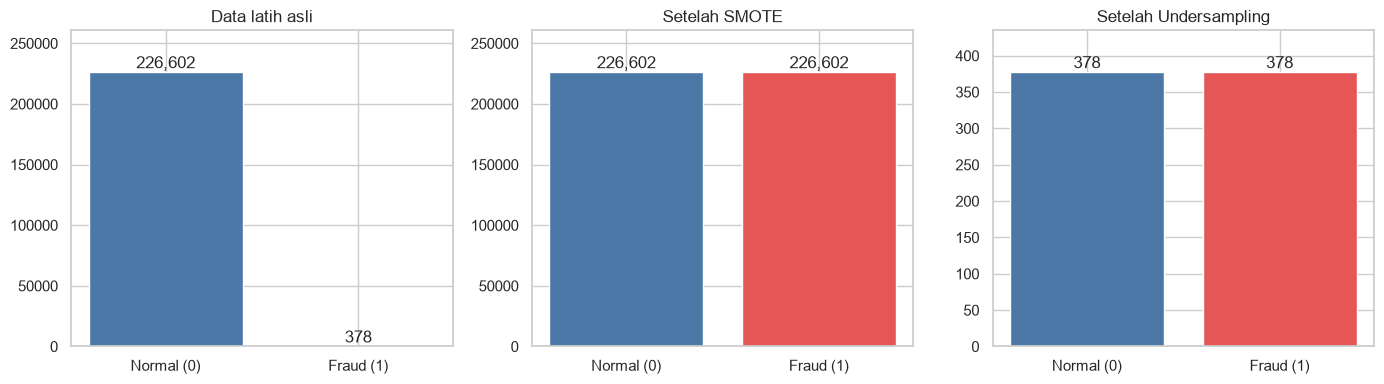

In [10]:
smote = SMOTE(random_state=RANDOM_STATE)
X_smote, y_smote = smote.fit_resample(X_train, y_train)

rus = RandomUnderSampler(random_state=RANDOM_STATE)
X_under, y_under = rus.fit_resample(X_train, y_train)

dist_train = pd.DataFrame({
    "Asli": y_train.value_counts().sort_index(),
    "SMOTE": pd.Series(y_smote).value_counts().sort_index(),
    "Undersampling": pd.Series(y_under).value_counts().sort_index(),
})
dist_train.index = ["0 (Normal)", "1 (Fraud)"]
display(dist_train)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (name, ys) in zip(axes, [("Data latih asli", y_train), ("Setelah SMOTE", y_smote),
                                 ("Setelah Undersampling", y_under)]):
    vc = pd.Series(ys).value_counts().sort_index()
    ax.bar(["Normal (0)", "Fraud (1)"], vc.values, color=["#4C78A8", "#E45756"])
    ax.set_title(name)
    for i, v in enumerate(vc.values):
        ax.text(i, v, f"{v:,}", ha="center", va="bottom")
    ax.set_ylim(0, vc.max() * 1.15)
plt.tight_layout()
plt.show()

## 4. Membangun Model Klasifikasi

Dua ensemble method dipakai:
- **Random Forest** (bagging): model utama, diuji pada 4 skenario (baseline, class weight, SMOTE, undersampling).
- **Gradient Boosting** (`HistGradientBoostingClassifier`): pembanding dari keluarga boosting, diuji pada 3 skenario.

Hyperparameter sengaja dibuat sama di semua skenario sehingga perbedaan hasil benar-benar berasal dari cara penanganan imbalance. Fungsi evaluasi di bawah menghitung semua metrik pada **data uji asli**.

In [11]:
results = []          # ringkasan metrik
cms = {}              # confusion matrix per model
curves = {}           # probabilitas prediksi untuk kurva ROC / PR
fitted = {}           # model terlatih

def evaluate(name, model, X_tr, y_tr):
    t0 = time.time()
    model.fit(X_tr, y_tr)
    fit_time = time.time() - t0

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred),
        "F1-score": f1_score(y_test, y_pred),
        "AUC-ROC": roc_auc_score(y_test, y_prob),
        "AUC-PR": average_precision_score(y_test, y_prob),
        "Waktu latih (s)": fit_time,
    })
    cms[name] = confusion_matrix(y_test, y_pred)
    curves[name] = y_prob
    fitted[name] = model

    tn, fp, fn, tp = cms[name].ravel()
    print(f"{name:<22} | TP={tp:>3} FN={fn:>3} FP={fp:>4} TN={tn:>6} | "
          f"P={results[-1]['Precision']:.3f} R={results[-1]['Recall']:.3f} "
          f"F1={results[-1]['F1-score']:.3f} AUC-ROC={results[-1]['AUC-ROC']:.3f} "
          f"AUC-PR={results[-1]['AUC-PR']:.3f} ({fit_time:.0f}s)")

def make_rf(**kw):
    return RandomForestClassifier(n_estimators=100, max_depth=12, n_jobs=-1,
                                  random_state=RANDOM_STATE, **kw)

def make_gb(**kw):
    return HistGradientBoostingClassifier(max_iter=200, learning_rate=0.1,
                                          random_state=RANDOM_STATE, **kw)

### 4.1 Random Forest

In [12]:
# (a) Tanpa penanganan imbalance
evaluate("RF - Baseline", make_rf(), X_train, y_train)

RF - Baseline          | TP= 69 FN= 26 FP=   2 TN= 56649 | P=0.972 R=0.726 F1=0.831 AUC-ROC=0.967 AUC-PR=0.795 (51s)


In [13]:
# (b) Cost-sensitive learning: bobot kelas seimbang pada setiap bootstrap sample
evaluate("RF - Class Weight", make_rf(class_weight="balanced_subsample"), X_train, y_train)

RF - Class Weight      | TP= 69 FN= 26 FP=   9 TN= 56642 | P=0.885 R=0.726 F1=0.798 AUC-ROC=0.964 AUC-PR=0.795 (42s)


In [14]:
# (c) Oversampling dengan SMOTE
evaluate("RF - SMOTE", make_rf(), X_smote, y_smote)

RF - SMOTE             | TP= 76 FN= 19 FP=  30 TN= 56621 | P=0.717 R=0.800 F1=0.756 AUC-ROC=0.977 AUC-PR=0.796 (93s)


In [15]:
# (d) Random undersampling
evaluate("RF - Undersampling", make_rf(), X_under, y_under)

RF - Undersampling     | TP= 82 FN= 13 FP= 938 TN= 55713 | P=0.080 R=0.863 F1=0.147 AUC-ROC=0.978 AUC-PR=0.697 (0s)


### 4.2 Gradient Boosting

In [16]:
evaluate("GB - Baseline", make_gb(), X_train, y_train)

GB - Baseline          | TP= 66 FN= 29 FP=  65 TN= 56586 | P=0.504 R=0.695 F1=0.584 AUC-ROC=0.765 AUC-PR=0.528 (1s)


In [17]:
evaluate("GB - Class Weight", make_gb(class_weight="balanced"), X_train, y_train)

GB - Class Weight      | TP= 77 FN= 18 FP=  84 TN= 56567 | P=0.478 R=0.811 F1=0.602 AUC-ROC=0.958 AUC-PR=0.719 (2s)


In [18]:
evaluate("GB - SMOTE", make_gb(), X_smote, y_smote)

GB - SMOTE             | TP= 75 FN= 20 FP=  52 TN= 56599 | P=0.591 R=0.789 F1=0.676 AUC-ROC=0.959 AUC-PR=0.748 (8s)


## 5. Evaluasi Model

### 5.1 Tabel perbandingan metrik (kelas fraud, data uji asli)

In [19]:
res = pd.DataFrame(results).set_index("Model")
metric_cols = ["Accuracy", "Precision", "Recall", "F1-score", "AUC-ROC", "AUC-PR"]
(res[metric_cols + ["Waktu latih (s)"]]
    .round(4)
    .style.background_gradient(cmap="Greens", subset=["Precision", "Recall", "F1-score", "AUC-ROC", "AUC-PR"])
    .format({"Waktu latih (s)": "{:.0f}"}))

,Accuracy,Precision,Recall,F1-score,AUC-ROC,AUC-PR,Waktu latih (s)
Model,,,,,,,
RF - Baseline,0.999500,0.971800,0.726300,0.831300,0.966800,0.795400,51
RF - Class Weight,0.999400,0.884600,0.726300,0.797700,0.964100,0.795300,42
RF - SMOTE,0.999100,0.717000,0.800000,0.756200,0.976900,0.795700,93
RF - Undersampling,0.983200,0.080400,0.863200,0.147100,0.978100,0.697400,0
GB - Baseline,0.998300,0.503800,0.694700,0.584100,0.764800,0.527800,1
GB - Class Weight,0.998200,0.478300,0.810500,0.601600,0.957700,0.719000,2
GB - SMOTE,0.998700,0.590600,0.789500,0.675700,0.958600,0.747900,8


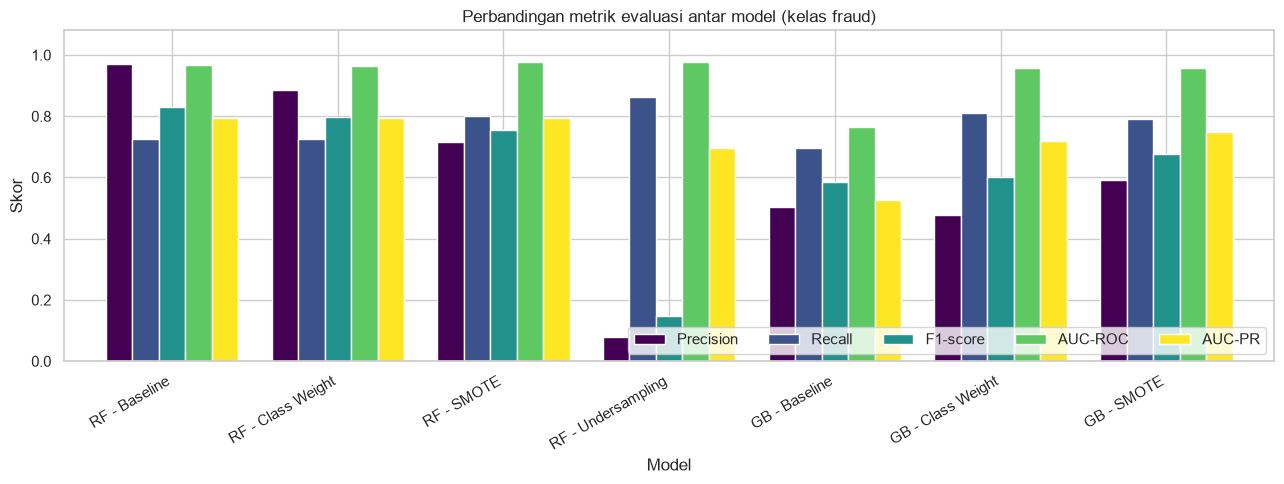

In [20]:
fig, ax = plt.subplots(figsize=(13, 5))
plot_df = res[["Precision", "Recall", "F1-score", "AUC-ROC", "AUC-PR"]]
plot_df.plot(kind="bar", ax=ax, width=0.8, colormap="viridis")
ax.set_title("Perbandingan metrik evaluasi antar model (kelas fraud)")
ax.set_ylabel("Skor")
ax.set_ylim(0, 1.08)
ax.legend(loc="lower right", ncol=5)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### 5.2 Confusion matrix

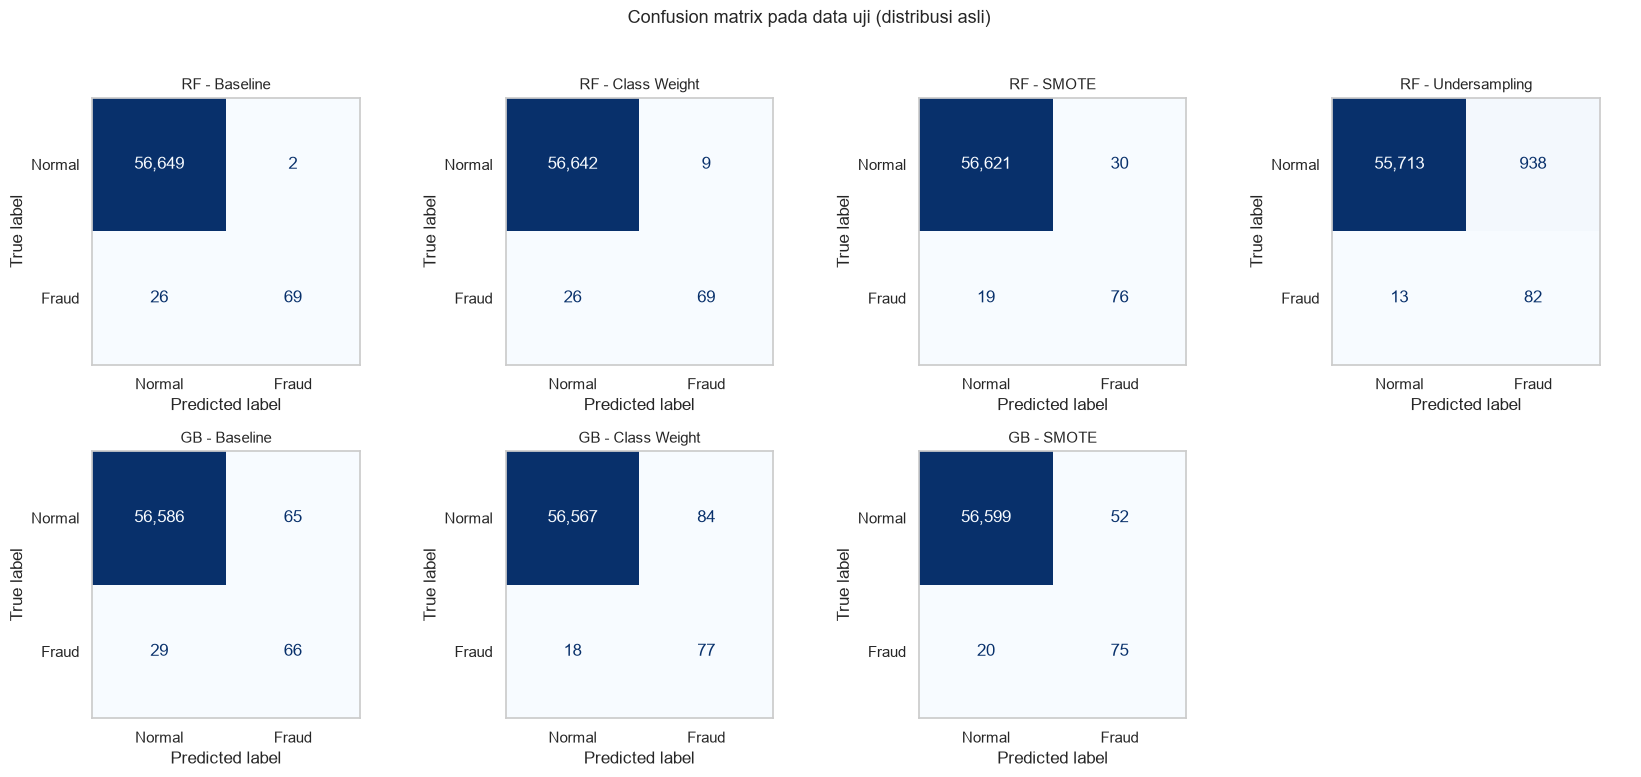

In [21]:
names = list(cms.keys())
n_cols = 4
n_rows = int(np.ceil(len(names) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.2 * n_cols, 3.8 * n_rows))
axes = axes.ravel()
for ax, name in zip(axes, names):
    disp = ConfusionMatrixDisplay(cms[name], display_labels=["Normal", "Fraud"])
    disp.plot(ax=ax, cmap="Blues", colorbar=False, values_format=",d")
    ax.set_title(name, fontsize=11)
    ax.grid(False)
for ax in axes[len(names):]:
    ax.axis("off")
plt.suptitle("Confusion matrix pada data uji (distribusi asli)", y=1.02, fontsize=13)
plt.tight_layout()
plt.show()

Cara membaca: baris = kelas sebenarnya, kolom = prediksi model. Sel kiri-bawah (**FN**) adalah fraud yang lolos tidak terdeteksi, sedangkan sel kanan-atas (**FP**) adalah transaksi normal yang salah ditandai sebagai fraud (*false alarm*).

### 5.3 Kurva ROC dan Precision-Recall

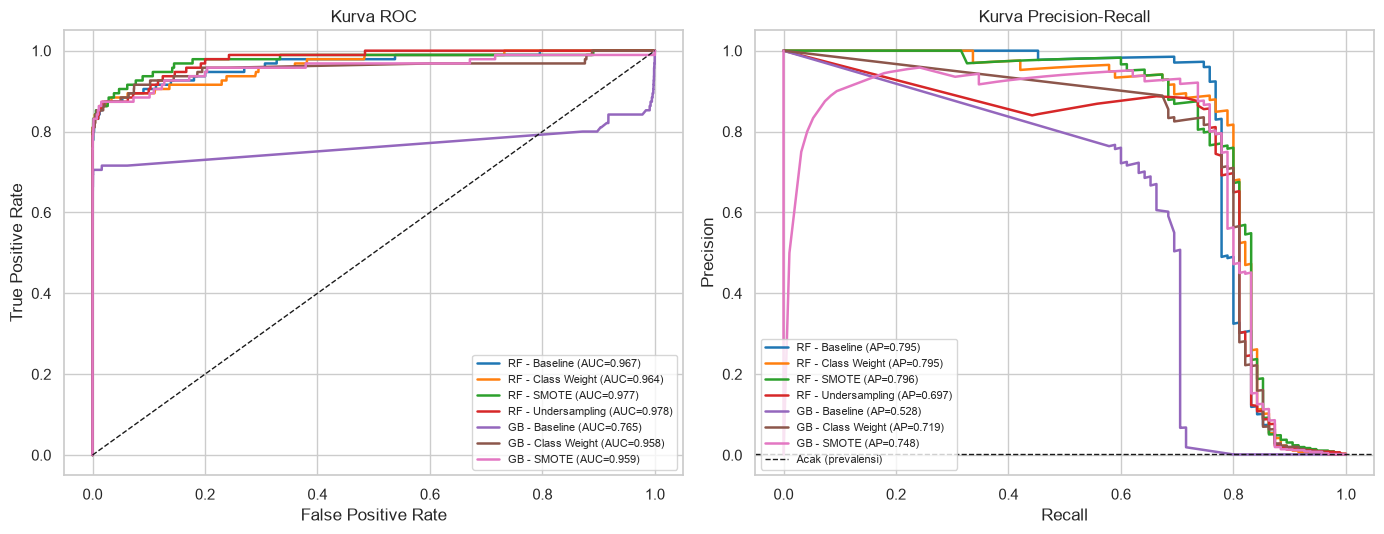

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
palette = sns.color_palette("tab10", len(curves))
for color, (name, prob) in zip(palette, curves.items()):
    fpr, tpr, _ = roc_curve(y_test, prob)
    ax[0].plot(fpr, tpr, color=color, lw=1.8,
               label=f"{name} (AUC={roc_auc_score(y_test, prob):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, prob)
    ax[1].plot(rec, prec, color=color, lw=1.8,
               label=f"{name} (AP={average_precision_score(y_test, prob):.3f})")

ax[0].plot([0, 1], [0, 1], "k--", lw=1)
ax[0].set(xlabel="False Positive Rate", ylabel="True Positive Rate", title="Kurva ROC")
ax[0].legend(fontsize=8, loc="lower right")

ax[1].axhline(y_test.mean(), color="k", ls="--", lw=1, label="Acak (prevalensi)")
ax[1].set(xlabel="Recall", ylabel="Precision", title="Kurva Precision-Recall")
ax[1].legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.show()

### 5.4 Laporan klasifikasi lengkap (model terbaik berdasarkan F1-score)

In [23]:
best_name = res["F1-score"].idxmax()
print("Model terbaik (F1 tertinggi):", best_name, "\n")
print(classification_report(y_test, fitted[best_name].predict(X_test),
                            target_names=["Normal (0)", "Fraud (1)"], digits=4))

Model terbaik (F1 tertinggi): RF - Baseline 

              precision    recall  f1-score   support

  Normal (0)     0.9995    1.0000    0.9998     56651
   Fraud (1)     0.9718    0.7263    0.8313        95

    accuracy                         0.9995     56746
   macro avg     0.9857    0.8631    0.9155     56746
weighted avg     0.9995    0.9995    0.9995     56746



### 5.5 Fitur paling berpengaruh (Random Forest)

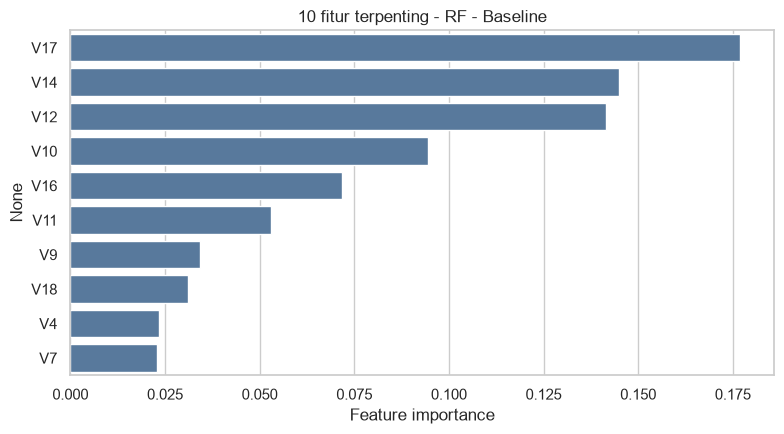

In [24]:
rf_models = [n for n in fitted if n.startswith("RF")]
best_rf = res.loc[rf_models, "F1-score"].idxmax()
imp = pd.Series(fitted[best_rf].feature_importances_, index=X_train.columns).sort_values(ascending=False).head(10)

plt.figure(figsize=(8, 4.5))
sns.barplot(x=imp.values, y=imp.index, color="#4C78A8")
plt.title(f"10 fitur terpenting - {best_rf}")
plt.xlabel("Feature importance")
plt.tight_layout()
plt.show()

## 6. Mengapa Accuracy Saja Tidak Cukup?

Untuk membuktikannya, berikut model "bodoh" yang **selalu memprediksi transaksi normal** tanpa mempelajari apa pun.

In [25]:
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
yd = dummy.predict(X_test)

print(f"Accuracy  : {accuracy_score(y_test, yd):.4f}")
print(f"Precision : {precision_score(y_test, yd, zero_division=0):.4f}")
print(f"Recall    : {recall_score(y_test, yd):.4f}")
print(f"F1-score  : {f1_score(y_test, yd):.4f}")
print(f"Fraud tertangkap: 0 dari {int(y_test.sum())}")

cmp = res[["Accuracy", "Recall", "F1-score"]].copy()
cmp.loc["Dummy (selalu 'normal')"] = [accuracy_score(y_test, yd), recall_score(y_test, yd), f1_score(y_test, yd)]
cmp.round(4)

Accuracy  : 0.9983
Precision : 0.0000
Recall    : 0.0000
F1-score  : 0.0000
Fraud tertangkap: 0 dari 95


,Accuracy,Recall,F1-score
Model,,,
RF - Baseline,0.9995,0.7263,0.8313
RF - Class Weight,0.9994,0.7263,0.7977
RF - SMOTE,0.9991,0.8000,0.7562
RF - Undersampling,0.9832,0.8632,0.1471
GB - Baseline,0.9983,0.6947,0.5841
GB - Class Weight,0.9982,0.8105,0.6016
GB - SMOTE,0.9987,0.7895,0.6757
Dummy (selalu 'normal'),0.9983,0.0000,0.0000


Model yang tidak mendeteksi satu pun fraud tetap memperoleh **accuracy sekitar 99,8%**, hanya terpaut sekitar 0,1 poin persentase dari model ensemble yang benar-benar bekerja (accuracy ≈ 99,95%). Alasannya, mayoritas data adalah transaksi normal, sehingga accuracy hanya mencerminkan seberapa baik model menebak kelas mayoritas. Oleh karena itu, untuk deteksi fraud digunakan:

- **Recall**: berapa persen fraud yang berhasil tertangkap. Fraud yang lolos berarti kerugian langsung.
- **Precision**: dari semua transaksi yang ditandai fraud, berapa persen yang benar-benar fraud. Precision rendah berarti banyak *false alarm* dan nasabah yang terganggu.
- **F1-score**: rata-rata harmonik precision dan recall.
- **AUC-ROC**: kemampuan model memisahkan kedua kelas di semua threshold.
- **AUC-PR**: seperti AUC-ROC tetapi lebih jujur pada data sangat tidak seimbang, karena tidak terpengaruh jumlah besar *true negative*.

## 7. Analisis Perbandingan & Kesimpulan

**Ringkasan hasil pada data uji (95 transaksi fraud dari 56.746 transaksi)**

| Model | Precision | Recall | F1 | AUC-ROC | AUC-PR | Fraud lolos (FN) | False alarm (FP) |
|---|---|---|---|---|---|---|---|
| RF - Baseline | 0,972 | 0,726 | **0,831** | 0,967 | 0,795 | 26 | 2 |
| RF - Class Weight | 0,885 | 0,726 | 0,798 | 0,964 | 0,795 | 26 | 9 |
| RF - SMOTE | 0,717 | 0,800 | 0,756 | 0,977 | **0,796** | 19 | 30 |
| RF - Undersampling | 0,080 | **0,863** | 0,147 | **0,978** | 0,697 | **13** | 938 |
| GB - Baseline | 0,584 | 0,768 | 0,664 | 0,838 | 0,689 | 22 | 52 |
| GB - Class Weight | 0,369 | 0,832 | 0,511 | 0,973 | 0,729 | 16 | 135 |
| GB - SMOTE | 0,615 | 0,789 | 0,691 | 0,963 | 0,752 | 20 | 47 |

**Temuan utama**

1. **Ada trade-off precision vs recall.** Pada Random Forest, semakin agresif penanganan imbalance, semakin banyak fraud yang tertangkap (recall 72,6% → 80,0% dengan SMOTE → 86,3% dengan undersampling), tetapi precision turun tajam (97,2% → 71,7% → 8,0%). Pada undersampling, 13 fraud lolos tetapi ada 938 transaksi normal yang salah ditandai, sehingga tidak praktis dipakai langsung.
2. **Pada Random Forest, penanganan imbalance lebih banyak menggeser titik keputusan daripada meningkatkan kemampuan memisahkan kelas.** AUC-PR RF Baseline, Class Weight, dan SMOTE hampir identik (≈ 0,795), artinya urutan skor risiko yang dihasilkan hampir sama bagusnya; yang berubah adalah seberapa mudah model memberi label "fraud". Karena itu F1 tertinggi justru dicapai RF Baseline, sedangkan RF SMOTE unggul pada recall dan AUC-ROC.
3. **Gradient Boosting mendapat manfaat yang lebih jelas dari penanganan imbalance.** F1 naik dari 0,664 (baseline) ke 0,691 (SMOTE), AUC-PR naik dari 0,689 ke 0,752, dan AUC-ROC naik dari 0,838 ke 0,963–0,973. Kurva ROC GB Baseline terlihat jatuh di area FPR tinggi, kemungkinan karena skor probabilitas yang tidak stabil saat kelas fraud sangat sedikit.
4. **Dengan pengaturan yang sama, Random Forest mengungguli Gradient Boosting** pada F1 dan AUC-PR di semua skenario. Perlu diingat GB belum di-tuning.
5. **Accuracy tidak informatif**: semua model (dan model dummy yang tidak menangkap satu pun fraud) memiliki accuracy di atas 99,8%, sehingga pemilihan model harus berdasarkan recall, precision, F1, dan AUC-PR.

**Rekomendasi.** Bila yang diutamakan keseimbangan precision-recall, **RF Baseline** (F1 = 0,831) adalah pilihan terbaik. Bila kerugian akibat fraud yang lolos jauh lebih besar daripada biaya memeriksa false alarm, **RF + SMOTE** lebih sesuai karena recall naik menjadi 80% dengan hanya 30 false alarm.

**Keterbatasan**
- Data uji hanya memuat 95 fraud, sehingga selisih beberapa transaksi saja dapat mengubah metrik cukup besar; hasil dari satu kali split belum tentu stabil. Cross-validation berulang akan memberi gambaran yang lebih kuat.
- Hyperparameter tidak di-tuning dan threshold klasifikasi tetap 0,5. Mengatur threshold (misalnya dari kurva Precision-Recall) bisa menggeser trade-off tanpa mengubah model.
- Baris duplikat dihapus sebelum split (283.726 baris), sehingga angkanya sedikit berbeda dari dataset asli 284.807 baris.